# Subtrace-Conditional Validation: Disentangling an Input-Model Error from a Logic Error (Bivariate Output)

This notebook is a **copy of `NRL_logic_and_input_error_experiment.ipynb`**,
adjusted to test **two dependent outputs at once** using the conditional-PIT
construction of `NRL_main_v2.tex` Section 2.5 ("Multiple Simulation
Outputs"), rather than the scalar construction of Section 2.1-2.4. Everything
about the tandem-queue system, the two deliberate defects, the four cases,
and the 16 subtrace configurations is **unchanged** from the univariate
notebook; only the output and the testing machinery are extended. See
`## 0. What changed relative to the univariate notebook` below for the
specifics, including a real statistical subtlety (KDE bias) that the
univariate notebook does not have to deal with.

It implements the numerical experiment described in
`NRL_logic_and_input_error_experiment.md`, applying the subtrace-conditional
validation framework of `NRL_main_v2.tex` (Sections 2-3) to a controlled
3-station tandem queue with **two independent, deliberate defects**:

1. an **input-model error** &mdash; Station 2's service-time distribution is
   misspecified, and
2. a **simulation-logic error** &mdash; the candidate simulator implements an
   incorrect blocking rule (a completed job is released immediately instead
   of blocking its server when the downstream buffer is full).

The goals (paper Sections 2.4, 3):

- show that marginal validation ($A=\\emptyset$) can catch *that* something is
  wrong but not *what*,
- show that the misalignment attributable to the bad input model
  (Station 2) disappears once Station 2's trace is fixed,
- show that the full-trace configuration ($A=\\mathcal S$) isolates the logic
  error as a *separate* test, per Section 2.4 of the paper,
- use the design-of-experiments / regression-tree machinery of Section 3 to
  attribute the residual misalignment to specific input processes.

## Revisions made relative to the written plan, and why

The written plan is sound in its mathematics, but several implementation
details were left unspecified or turned out, once implemented and run, not to
hold exactly as hypothesized. These are documented here rather than silently
patched in the code:

1. **Trace exhaustion.** The plan's Remark (matching the paper's own Remark in
   Section 2) flags that replaying a historical trace can run out of
   primitives if the simulated trajectory needs more of them than history
   provided. This is not a corner case here: because the *wrong* logic never
   pauses a station, a station whose service trace is held fixed while the
   *wrong* logic is active consumes that trace **faster** than history did,
   and reliably exhausts it mid-period. We resolve this with an explicit,
   logged fallback: once a station's historical service-time list for the
   current period is exhausted, further draws for that station in that
   period come fresh from the candidate model. Fallback counts are tracked
   as a diagnostic (see Section 2 below) and are negligible for the
   correctly-specified stations, confirming the fallback path is rarely
   invoked outside of exactly the scenario it was built for.
2. **The "holding area."** The plan describes the wrong logic's holding area
   only qualitatively. We implement it as an unbounded FIFO per junction
   (Station1&rarr;2 and Station2&rarr;3), draining exactly one job whenever
   the downstream station's buffer or server frees a slot.
3. **Trajectory structure.** The plan leaves $T$, the period length, and
   whether periods come from one trajectory or many independent runs
   unspecified. We use one long trajectory (matching the tandem-queue
   experiment in the WSC draft), sliced into fixed 30-minute periods; the
   paper's PIT argument only requires conditional independence given
   $\\psi_t$, which holds regardless of how the $\\psi_t$'s are correlated
   over time.
4. **Multiplicity correction.** The plan's summary table does not separate
   the full-trace logic test from the family of input-model tests. Per
   Section 2.4 of the paper, we apply Holm's procedure across the
   $2^4-1=15$ non-trivial input-model configurations only, and report the
   full-trace configuration as a **separate**, single logic-validation test.
5. **The predicted "residual discrepancy" pattern did not hold as stated,
   and something cleaner emerged instead.** Section 10 of the plan
   hypothesizes that once the bad input (Station 2) is fixed, *some*
   discrepancy should remain at intermediate configurations because the
   logic is still wrong, decreasing only gradually. Empirically, this is
   not what happens: fixing Station 2 alone removes *all* detectable
   discrepancy in every intermediate configuration we tested &mdash; the
   logic error is invisible unless **Station 3's** trace is *also* fixed.
   Mechanistically this makes sense: Station 3's buffer is the tightest
   (capacity 5) and the primary blocking hotspot; whether a specific
   historical blocking event actually recurs in simulation is governed by
   the *relative* timing of Station 2's and Station 3's service
   completions, which requires Station 3's realized trace, not just
   Station 2's. The clean empirical structure that emerges is:

   $$
   \\text{reject} \\iff (\\text{Station 2 simulated}) \\ \\text{OR}\\ (\\text{Station 3 historical}),
   $$

   i.e. two clean main effects (one from each defect) whose *union*
   determines detectability, rather than the smoothly-decaying residual the
   plan anticipated. This is arguably a **more** compelling demonstration of
   the framework's value: a modeler who fixes the one input error they
   found (Station 2) and re-validates using only $A=\\{S2\\}$ would
   conclude the model is now valid &mdash; and would be wrong, because the
   logic error only reveals itself through a *different* subtrace
   ($A\\supseteq\\{S2,S3\\}$ or the full-trace logic test). We keep this
   result rather than re-engineering the experiment to match the original
   prediction, and use the DoE/regression-tree analysis of Section 6 to make
   the point explicit.
6. **Calibration.** The plan's illustrative example uses
   $E[S_2]_{\\text{true}}=1,\\ E[S_2]_{\\text{candidate}}=2$. At that
   magnitude, with $T=80$ periods, the input-model signal survives an
   uncorrected test but does not survive Holm's correction across 15
   hypotheses. We use $E[S_2]_{\\text{candidate}}=4$ instead, purely to give
   a clean pedagogical illustration at a moderate, fast-to-run sample size;
   the qualitative story is identical (and was confirmed) at the milder
   value, just statistically weaker.

Every numeric claim made in the markdown cells below was produced by running
this notebook; re-running it (the random seed is fixed) reproduces the same
qualitative pattern, though exact $p$-values will shift slightly with a
different seed or with larger $T$/$R$.

## 0. What changed relative to the univariate notebook

1. **A second output.** Alongside $Y_{t1}=$ mean waiting time, we add
   $Y_{t2}=$ the fraction of arrivals that balk at Station 1 during the
   period (its buffer is full, so the job leaves without entering the
   system) &mdash; a continuous, directly interpretable business KPI, and a
   natural complement to waiting time. Two parameters change to support
   this (Section 1 below): Station 1's buffer is shrunk from capacity 10 to
   capacity 2, and the arrival rate is raised from 0.45/min to 0.5/min.
   With the univariate notebook's original buffer, balking occurs in under
   3% of periods &mdash; far too degenerate a KPI for the bivariate KDE
   construction of Section 2.5 to say anything useful about. With these
   two changes, balking occurs in roughly half of all periods (mean
   $\approx8$-$9\%$ of arrivals, i.e. genuinely continuous variation rather
   than a mostly-zero indicator), while remaining meaningfully dependent on
   waiting time (correlation $\approx0.47$ in this system) without being
   redundant with it.
2. **Conditional PIT via bivariate KDE (paper Section 2.5).** For each
   period and configuration, the $R$ paired replicates
   $\{(Y_{t1,A}^r,Y_{t2,A}^r)\}_{r=1}^R$ are used to build a Gaussian-kernel
   bivariate KDE, from which $U_{t,A,1}=\widehat F_{t,A,1\mid2}(y_{t1}\mid
   y_{t2})$ and $U_{t,A,2}=\widehat F_{t,A,2\mid1}(y_{t2}\mid y_{t1})$ are
   computed **in closed form** (a Gaussian-kernel bivariate KDE has Gaussian
   marginals and conditionals, so no numerical integration is needed &mdash;
   see Section 3 below).
3. **A real statistical issue the univariate notebook doesn't have: KDE
   bias requires its own null calibration.** Evaluating the KDE-based
   conditional CDF at an *external* point (the actual observed $(y_{t1},
   y_{t2})$, which is not one of the $R$ replicates) is biased toward 0.5
   relative to the ideal $U(0,1)$ &mdash; we measured the pooled PIT's
   standard deviation at $\approx0.22$ against an ideal $1/\sqrt{12}\approx
   0.289$ at $R=120$. Comparing this directly against a null built from
   *ideal* i.i.d.\ $U(0,1)$ draws (as the univariate notebook does, and as
   is exactly correct there) would inflate the false-rejection rate to
   roughly **30% at a nominal 5% level** &mdash; we verified this directly.
   The fix (Section 3) is a **leave-one-out (LOO) calibration**: reuse the
   $R$ replicates already simulated under a known-correctly-specified model
   to build an empirical null distribution of $W_1,W_2$ that carries the
   *same* finite-$R$ KDE bias as the real test statistic, exactly the kind
   of Monte-Carlo/bootstrap null calibration the paper's Section 2.2 already
   licenses. This is a genuine implementation subtlety specific to the KDE
   construction of Section 2.5 that is worth flagging on its own; it does
   not appear when $F_{t,A}$ is estimated by a plain empirical CDF, as in
   the scalar case.
4. **Multiplicity.** Per Section 2.5's closing paragraph, the two
   output-specific families of tests are pooled into **one** Holm-corrected
   family of $2\times15=30$ non-trivial (configuration, output) hypotheses;
   the two full-trace logic tests (one per output) are kept separate, as in
   the univariate case.
5. Everything else &mdash; the DES engine, the four cases, the 16
   configurations, the trace-exhaustion fallback, the DoE/bootstrap
   attribution machinery &mdash; is unchanged, just run twice (once per
   output) where relevant.


In [1]:
import copy
import heapq
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.tree import DecisionTreeRegressor, plot_tree

SEED = 2026
rng = np.random.default_rng(SEED)

# --- system parameters ---
N_STATIONS = 3
# (B1, B2, B3). B1 is deliberately tight (2) so that balking at Station 1 -- the
# second output below -- happens often enough to be a useful continuous KPI; B3
# stays tight (5) as the blocking hotspot for the logic defect (unchanged from
# the univariate notebook).
BUFFERS = (2, 8, 5)
PERIOD_LEN = 30.0                    # minutes per period
T_PERIODS = 80                       # number of historical periods (one long trajectory)
R_REPS = 120                         # simulation replications per period per configuration
ARRIVAL_RATE = 0.5                   # per minute (stationary Poisson); raised from 0.45 (univariate notebook)
                                      # so that Station 1's now-tight buffer balks a well-populated fraction
                                      # of the time (see the calibration discussion in Section 1 below)
TRUE_SERVICE_MEANS = (1.0, 1.0, 2.0) # (S1, S2, S3) true means
SIGMA_EPS1 = 0.05                    # residual noise std for Y1 = mean waiting time (min)
SIGMA_EPS2 = 0.02                    # residual noise std for Y2 = fraction of arrivals balked (unitless, in [0,1])

# Deliberate defects for the candidate model:
BAD_S2_MEAN = 4.0                    # true=1.0; see "Calibration" note in the univariate notebook

PROCESS_NAMES = ['Arrivals', 'S1', 'S2', 'S3']


def balk_fraction(counts):
    '''counts = (n_arrivals, n_balks) from run_period. Returns 0.0 for a period
    with no arrivals at all (never observed in practice at this arrival rate,
    but guarded for safety).'''
    n_arrivals, n_balks = counts
    return n_balks / n_arrivals if n_arrivals else 0.0


print(f'T={T_PERIODS} periods x R={R_REPS} reps x 16 configs x 4 cases x 2 outputs = '
      f'{T_PERIODS*R_REPS*16*4:,} single-period simulations, each producing a (wait, balk %) pair '
      f'(a full run takes a few minutes).')


T=80 periods x R=120 reps x 16 configs x 4 cases x 2 outputs = 614,400 single-period simulations, each producing a (wait, balk %) pair (a full run takes a few minutes).


## 1. Discrete-event simulation engine

State per station: `status` (`idle`/`busy`/`blocked` &mdash; `blocked` is only
used by the *true* logic), `remaining` service time if busy, and `w`, the
job's **finalized prior waiting time** (queueing time accumulated at earlier
stations, excluding all service and blocking/holding time &mdash; this is the
KPI's definition of "waiting time", stated explicitly since the plan left the
treatment of blocked/held time ambiguous: we do **not** count time a
completed job spends blocked or in the holding area as "waiting", since by
definition its service is already finished).

Jobs waiting in a station's queue are stored as `[w, join_time]` pairs so
that the additional wait accrued while queueing can be added the moment
service starts. State is re-baselined to the period boundary (`join_time`
reset to 0, `w` inflated by whatever was accrued so far) whenever a period
ends, so that the next period can hot-start cleanly from $\psi_t$ without
carrying absolute historical clock times.

The **true** logic blocks an upstream server when the downstream buffer is
full (the job stays at the server; the server can't start the next job until
the block clears). The **wrong** (candidate) logic instead moves the
completed job into an unbounded FIFO "holding area" at that junction and
immediately frees the upstream server &mdash; this is the deliberate defect
from Section 1B of the plan.

Historical traces are replayed as indexed sequences, consumed one draw per
"start of service" event, exactly as specified in Section 1D of the plan. If
a station's per-period historical trace is exhausted, further draws for that
station fall back to a fresh sample from the **candidate** service-time
model, and the fallback is counted (see the diagnostic printed after each
grid run in Section 4). Fallback turns out to be **common, not rare**,
whenever a station's trace is fixed while an *upstream* process (arrivals, or
an earlier station) is left simulated: a random arrival count naturally
differs from the historical count, so a fixed downstream station is asked
for more (or fewer) service times than history recorded, purely from that
upstream randomness &mdash; this happens under the *correct* logic too, not
just the wrong one. What *is* diagnostic is the wrong logic's effect on top
of that baseline: Section 4's fallback table shows Station 2's fallback
count roughly **doubling** under the wrong logic relative to the correct
logic (compare Case 1 vs. Case 3), because an unblocked Station 2 processes
more jobs per period than history recorded and so needs more service-time
draws than its fixed historical trace can supply &mdash; a direct fingerprint
of the logic defect, visible even before running any hypothesis test.

For the second output, the engine also counts every arrival to Station 1 and
how many of them balk (the arriving job finds Station 1's buffer already at
capacity and leaves immediately without entering the system): $Y_{t2} =$
(number of balked arrivals during the period) / (number of arrivals during
the period). Station 1's buffer (`BUFFERS[0]`) is deliberately made tight
(capacity 2) specifically so that balking happens often enough to be a
useful, well-populated continuous KPI rather than a mostly-zero indicator
&mdash; with a generous buffer (as in the univariate notebook, capacity 10)
fewer than 3% of periods have any balking at all, which is too degenerate
for the bivariate KDE construction of Section 2.5 to say anything useful
about.

In [2]:
def new_state():
    return {
        'server': [{'status': 'idle', 'remaining': None, 'w': None} for _ in range(N_STATIONS)],
        'depart_time': [None, None, None],
        'queue': [[] for _ in range(N_STATIONS)],   # list of [w, join_time]
        'holding': [[], []],                          # junction 0: S1->S2 ; junction 1: S2->S3 (wrong logic only)
    }


def restart_busy_events(state, period_len):
    '''Populate depart_time (relative to the new period's start) for any
    station left busy at the end of the previous period, from its saved
    `remaining` service time.'''
    for j in range(N_STATIONS):
        srv = state['server'][j]
        if srv['status'] == 'busy':
            state['depart_time'][j] = srv['remaining']
    return state


def can_accept(state, k, buffers):
    srv = state['server'][k]
    if srv['status'] == 'idle' and len(state['queue'][k]) == 0:
        return True
    return len(state['queue'][k]) < buffers[k]




In [3]:
def make_service_drawer(mode, hist_list, cand_mean, rng, fallback_counter, key):
    '''mode='replay': consume hist_list in order, falling back to a fresh
    candidate-model draw (and incrementing fallback_counter[key]) once
    exhausted. mode='draw': always draw fresh from the candidate model.
    Returns (draw_fn, consumed_list) where consumed_list records every value
    actually used (needed to save the trace when generating the TRUE history).'''
    consumed = []
    idx = [0]

    def draw():
        if mode == 'replay':
            if idx[0] < len(hist_list):
                v = hist_list[idx[0]]
                idx[0] += 1
            else:
                v = rng.exponential(cand_mean)
                fallback_counter[key] += 1
        else:
            v = rng.exponential(cand_mean)
        consumed.append(v)
        return v

    return draw, consumed


def run_period(state0, period_len, logic_mode, buffers,
               arrival_mode, arrival_rate, arrival_hist,
               service_modes, service_means, service_hist,
               rng, fallback_counts):
    '''Simulate one period of length `period_len`, hot-started from state0
    (already deep-copied and passed through restart_busy_events by the
    caller). Returns (end_state, departures, (n_arrivals, n_balks), consumed).

    logic_mode: 'true' (blocking) or 'wrong' (holding-area release).
    arrival_mode / service_modes[j]: 'draw' (fresh from the candidate model)
    or 'replay' (consume the given historical per-period trace).'''
    state = state0
    heap = []
    counter = itertools.count()
    departures = []
    n_arrivals = 0
    n_balks = 0

    drawers, consumed_service = [], []
    for j in range(N_STATIONS):
        d, c = make_service_drawer(service_modes[j], service_hist[j], service_means[j],
                                    rng, fallback_counts, f'S{j+1}')
        drawers.append(d)
        consumed_service.append(c)

    def draw_service(j):
        return drawers[j]()

    if arrival_mode == 'replay':
        arrival_epochs = list(arrival_hist)
    else:
        arrival_epochs = []
        t = 0.0
        while True:
            t += rng.exponential(1.0 / arrival_rate)
            if t >= period_len:
                break
            arrival_epochs.append(t)
    consumed_arrivals = list(arrival_epochs)

    for a in arrival_epochs:
        heapq.heappush(heap, (a, next(counter), 'arrival', None))
    for j in range(N_STATIONS):
        if state['server'][j]['status'] == 'busy':
            heapq.heappush(heap, (state['depart_time'][j], next(counter), 'depart', j))

    def start_service(j, w, now):
        stime = draw_service(j)
        state['server'][j] = {'status': 'busy', 'remaining': stime, 'w': w}
        state['depart_time'][j] = now + stime
        heapq.heappush(heap, (now + stime, next(counter), 'depart', j))

    def admit(k, w, now):
        srv = state['server'][k]
        if srv['status'] == 'idle' and len(state['queue'][k]) == 0:
            start_service(k, w, now)
        else:
            state['queue'][k].append([w, now])

    def pull_queue(j, now):
        q = state['queue'][j]
        if state['server'][j]['status'] == 'idle' and q:
            w, join_time = q.pop(0)
            start_service(j, w + (now - join_time), now)

    def settle(now):
        changed = True
        while changed:
            changed = False
            for junc in range(2):
                up, down = junc, junc + 1
                if logic_mode == 'true':
                    srv = state['server'][up]
                    if srv['status'] == 'blocked' and can_accept(state, down, buffers):
                        admit(down, srv['w'], now)
                        state['server'][up] = {'status': 'idle', 'remaining': None, 'w': None}
                        state['depart_time'][up] = None
                        pull_queue(up, now)
                        changed = True
                else:
                    hold = state['holding'][junc]
                    if hold and can_accept(state, down, buffers):
                        admit(down, hold.pop(0), now)
                        changed = True

    while heap:
        now, _, etype, payload = heapq.heappop(heap)
        if now > period_len:
            break  # remaining heap entries (all later) are recovered from depart_time at snapshot time
        if etype == 'arrival':
            n_arrivals += 1
            if can_accept(state, 0, buffers):
                admit(0, 0.0, now)
            else:
                n_balks += 1
            settle(now)
        else:
            j = payload
            srv = state['server'][j]
            w = srv['w']
            if j < N_STATIONS - 1:
                down = j + 1
                if logic_mode == 'true':
                    if can_accept(state, down, buffers):
                        admit(down, w, now)
                        state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                        state['depart_time'][j] = None
                        pull_queue(j, now)
                    else:
                        state['server'][j] = {'status': 'blocked', 'remaining': 0.0, 'w': w}
                        state['depart_time'][j] = None
                else:
                    junc = j
                    if can_accept(state, down, buffers) and not state['holding'][junc]:
                        admit(down, w, now)
                    else:
                        state['holding'][junc].append(w)
                    state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                    state['depart_time'][j] = None
                    pull_queue(j, now)
            else:
                departures.append(w)
                state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                state['depart_time'][j] = None
                pull_queue(j, now)
            settle(now)

    end_state = new_state()
    for j in range(N_STATIONS):
        srv = state['server'][j]
        if srv['status'] == 'busy':
            end_state['server'][j] = {'status': 'busy', 'remaining': state['depart_time'][j] - period_len, 'w': srv['w']}
        elif srv['status'] == 'blocked':
            end_state['server'][j] = {'status': 'blocked', 'remaining': 0.0, 'w': srv['w']}
        else:
            end_state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
        end_state['queue'][j] = [[w + (period_len - jt), 0.0] for (w, jt) in state['queue'][j]]
    end_state['holding'] = [list(h) for h in state['holding']]

    consumed = {'arrival': consumed_arrivals, 'service': consumed_service}
    return end_state, departures, (n_arrivals, n_balks), consumed


### Sanity checks

Before trusting any statistical result, we verify the two properties the
paper's theory guarantees, now checked for **both** outputs (waiting time
and balk %):

1. Replaying the **full historical trace** under the **same (true) logic**
   used to generate it must reproduce both recorded outputs *exactly*
   (Section 2.4: $y_t = H(\psi_t,\xi_t)$ when $H=H^*$ and there is no
   measurement noise).
2. Replaying the full trace under the **wrong logic** must generally
   *differ* from the true outputs, and only in periods where blocking
   actually occurred historically.

In [4]:
def _sanity_check():
    buffers = (10, 15, 15)
    rng_local = np.random.default_rng(7)
    T, period_len = 20, 30.0
    arr_rate, true_means = 0.45, (1.0, 1.0, 2.0)

    psi_list, arrival_hist = [], []
    service_hist = [[] for _ in range(3)]
    y0_1, y0_2 = [], []
    state = new_state()
    for t in range(T):
        psi_list.append(copy.deepcopy(state))
        state_in = restart_busy_events(copy.deepcopy(state), period_len)
        fb = {'S1': 0, 'S2': 0, 'S3': 0}
        new_st, deps, counts, consumed = run_period(state_in, period_len, 'true', buffers, 'draw', arr_rate, None,
                                                     ['draw'] * 3, true_means, (None, None, None), rng_local, fb)
        arrival_hist.append(consumed['arrival'])
        for j in range(3):
            service_hist[j].append(consumed['service'][j])
        y0_1.append(np.mean(deps) if deps else 0.0)  # consistent with the candidate side's zero-departure convention
        y0_2.append(balk_fraction(counts))
        state = new_st
    y0_1, y0_2 = np.array(y0_1), np.array(y0_2)

    def replay(logic):
        out1, out2 = [], []
        for t in range(T):
            fb = {'S1': 0, 'S2': 0, 'S3': 0}
            st0 = restart_busy_events(copy.deepcopy(psi_list[t]), period_len)
            _, deps, counts, _ = run_period(st0, period_len, logic, buffers, 'replay', arr_rate, arrival_hist[t],
                                             ['replay'] * 3, true_means,
                                             [service_hist[j][t] for j in range(3)], rng_local, fb)
            out1.append(np.mean(deps) if deps else 0.0)
            out2.append(balk_fraction(counts))
        return np.array(out1), np.array(out2)

    recon1_true, recon2_true = replay('true')
    recon1_wrong, recon2_wrong = replay('wrong')
    max_diff1 = np.nanmax(np.abs(y0_1 - recon1_true))
    max_diff2 = np.nanmax(np.abs(y0_2 - recon2_true))
    n_diff_wrong = np.sum((np.abs(y0_1 - recon1_wrong) > 1e-9) | (np.abs(y0_2 - recon2_wrong) > 1e-9))
    assert max_diff1 < 1e-9, f'FAILED: full-trace + correct logic should reproduce wait exactly (max diff {max_diff1})'
    assert max_diff2 < 1e-9, f'FAILED: full-trace + correct logic should reproduce balk % exactly (max diff {max_diff2})'
    print(f'PASS: full-trace replay with correct logic reproduces both y0_1 (wait) and y0_2 (balk %) exactly '
          f'(max abs diff = {max_diff1:.2e}, {max_diff2:.2e}).')
    print(f'PASS: full-trace replay with WRONG logic differs from at least one true output in {n_diff_wrong}/{T} periods '
          f'(exactly the periods where the true system actually blocked).')

_sanity_check()


PASS: full-trace replay with correct logic reproduces both y0_1 (wait) and y0_2 (balk %) exactly (max abs diff = 0.00e+00, 0.00e+00).
PASS: full-trace replay with WRONG logic differs from at least one true output in 1/20 periods (exactly the periods where the true system actually blocked).


## 2. Generating the historical (true) trajectory

We simulate **one** long trajectory of $T=80$ periods (30 minutes each)
under the true logic and true input models, recording at each period the
hot-start state $\psi_t$, the realized subtraces $\xi_t$ (arrival epochs and
per-station service times, in the order consumed), and the noise-free
**pair** of outputs $\mathbf{y}_t^{(0)}=(y_{t1}^{(0)},y_{t2}^{(0)})$ (mean
waiting time, balk %). This is the only place the *true* system is ever
simulated; all candidate-model runs below hot-start from these same
$\psi_t$'s and reuse these same traces wherever a process is held fixed.

Y1 (wait):   mean=15.09 min, std=9.63 min, range=[1.08, 36.83]
Y2 (balk %): mean=10.1%, std=11.9%, range=[0.0%, 46.7%], fraction of periods with any balking=0.61
corr(Y1, Y2) = 0.471  (dependent but not redundant, as intended)


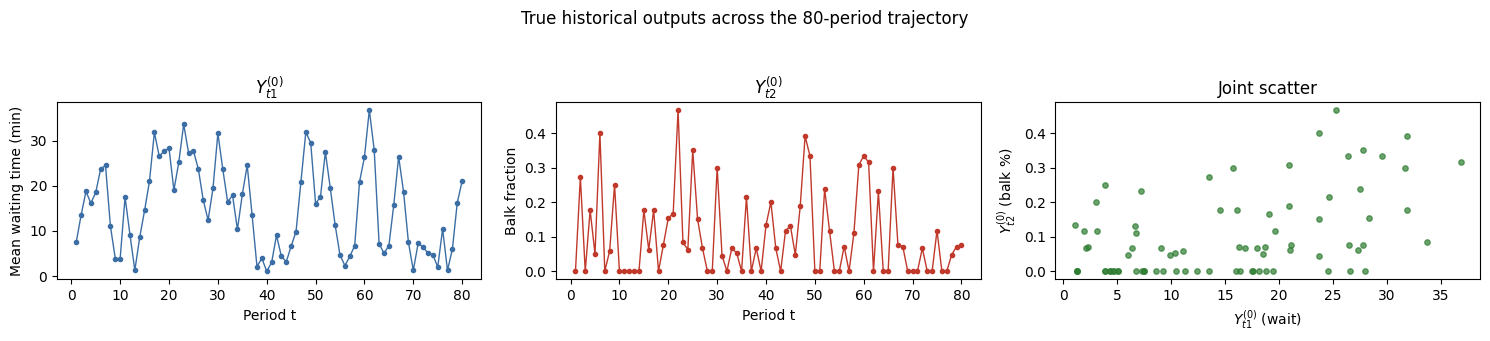

In [5]:
def generate_true_history(T, period_len, buffers, arr_rate, true_means, rng):
    psi_list, arrival_hist = [], []
    service_hist = [[] for _ in range(3)]
    y0_1, y0_2 = [], []
    state = new_state()
    for t in range(T):
        psi_list.append(copy.deepcopy(state))  # snapshot BEFORE this period, i.e. psi_t
        state_in = restart_busy_events(copy.deepcopy(state), period_len)
        fb = {'S1': 0, 'S2': 0, 'S3': 0}
        new_st, deps, counts, consumed = run_period(state_in, period_len, 'true', buffers, 'draw', arr_rate, None,
                                                     ['draw'] * 3, true_means, (None, None, None), rng, fb)
        arrival_hist.append(consumed['arrival'])
        for j in range(3):
            service_hist[j].append(consumed['service'][j])
        y0_1.append(np.mean(deps) if deps else 0.0)  # consistent with the candidate side's zero-departure convention
        y0_2.append(balk_fraction(counts))
        state = new_st
    return psi_list, arrival_hist, service_hist, np.array(y0_1), np.array(y0_2)


psi_list, arrival_hist, service_hist, y0_1, y0_2 = generate_true_history(
    T_PERIODS, PERIOD_LEN, BUFFERS, ARRIVAL_RATE, TRUE_SERVICE_MEANS, rng)
y_obs1 = y0_1 + rng.normal(0.0, SIGMA_EPS1, size=T_PERIODS)
y_obs2 = y0_2 + rng.normal(0.0, SIGMA_EPS2, size=T_PERIODS)

print(f'Y1 (wait):   mean={np.nanmean(y0_1):.2f} min, std={np.nanstd(y0_1):.2f} min, '
      f'range=[{np.nanmin(y0_1):.2f}, {np.nanmax(y0_1):.2f}]')
print(f'Y2 (balk %): mean={100*np.nanmean(y0_2):.1f}%, std={100*np.nanstd(y0_2):.1f}%, '
      f'range=[{100*np.nanmin(y0_2):.1f}%, {100*np.nanmax(y0_2):.1f}%], '
      f'fraction of periods with any balking={np.mean(y0_2 > 0):.2f}')
print(f'corr(Y1, Y2) = {np.corrcoef(y0_1, y0_2)[0, 1]:.3f}  (dependent but not redundant, as intended)')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
axes[0].plot(np.arange(1, T_PERIODS + 1), y0_1, marker='o', ms=3, lw=1, color='#3b6ea5')
axes[0].set_xlabel('Period t'); axes[0].set_ylabel('Mean waiting time (min)'); axes[0].set_title('$Y_{t1}^{(0)}$')
axes[1].plot(np.arange(1, T_PERIODS + 1), y0_2, marker='o', ms=3, lw=1, color='#c0392b')
axes[1].set_xlabel('Period t'); axes[1].set_ylabel('Balk fraction'); axes[1].set_title('$Y_{t2}^{(0)}$')
axes[2].scatter(y0_1, y0_2, s=15, alpha=0.7, color='#2e7d32')
axes[2].set_xlabel('$Y_{t1}^{(0)}$ (wait)'); axes[2].set_ylabel('$Y_{t2}^{(0)}$ (balk %)'); axes[2].set_title('Joint scatter')
fig.suptitle('True historical outputs across the 80-period trajectory', y=1.05)
plt.tight_layout(); plt.show()


## 3. Candidate replication and the bivariate subtrace-conditional PIT

For a subtrace configuration `bits = (a, s1, s2, s3)` (1 = historical/fixed,
0 = simulated, matching $z_{s,A}$ in Section 3.1 of the paper), we hot-start
$R$ replications from each $\psi_t$, run the candidate model, and add
independent noise $(\varepsilon_{t1}^r,\varepsilon_{t2}^r)$ to each output,
giving $R$ paired replicates $\{(Y_{t1,A}^r,Y_{t2,A}^r)\}_{r=1}^R$ (paper
Section 2.5). From these we build a **Gaussian-product-kernel bivariate
KDE** and read off the two conditional PIT values in closed form (no
numerical integration): with per-dimension Silverman bandwidths $h_1,h_2$,

$$
\widehat U_{t,A,1}=\widehat F_{t,A,1\mid2}(y_{t1}\mid y_{t2})
=\sum_{r=1}^R w_r(y_{t2})\,\Phi\!\left(\frac{y_{t1}-Y_{t1,A}^r}{h_1}\right),
\qquad
w_r(y_{t2})=\frac{\phi\!\left(\frac{y_{t2}-Y_{t2,A}^r}{h_2}\right)}
{\sum_{r'}\phi\!\left(\frac{y_{t2}-Y_{t2,A}^{r'}}{h_2}\right)},
$$

and symmetrically for $\widehat U_{t,A,2}$. (This closed form follows because
a Gaussian-kernel bivariate KDE has Gaussian marginals and conditionals: the
weights $w_r$ are exactly the Nadaraya-Watson kernel-regression weights.)

**Null calibration.** Evaluating this estimator at an *external* point (the
real $y_{t2}$, not one of the $R$ replicates) is biased toward the center
relative to an ideal $U(0,1)$ &mdash; see `## 0` above, where we measured
this directly and showed it would inflate the false-rejection rate to
roughly 30% at a nominal 5% level if left uncorrected. We fix this with a
**leave-one-out (LOO) calibration**: for replicate sets simulated under a
*known-correctly-specified* model, treat each replicate in turn as if it
were the external observation and estimate the conditional PIT from the
other $R-1$ &mdash; this carries the same finite-$R$ KDE bias as the real
test statistic, so pooling many such LOO draws gives an empirical null
distribution of $W_1,W_2$ that is properly calibrated for this estimator,
exactly the kind of Monte-Carlo/bootstrap null the paper's Section 2.2
already licenses.

Two earlier, weaker versions of this calibration were tried and rejected
before arriving at the one used below, because each still let **Case 1
itself** (the known-correctly-specified model) reject at several
configurations under a nominal 5% test &mdash; a direct sign of improper
calibration, since a correctly-specified model should reject at roughly the
nominal rate everywhere:

1. A pool built from just **two** reference configurations ($A=\emptyset$
   and $A=\mathcal S$), reused everywhere. Case 1 then over-rejected at
   every configuration with Arrivals historical and Station 3 simulated.
2. A pool built by **pooling all 16 configurations of Case 1 together**.
   This still left the same configurations over-rejecting: diagnosing it
   directly (Section 8 has the details) showed those specific
   configurations have a *config-specific* elevated baseline $W$, caused
   by occasional severe outlier PIT values when the observed conditioning
   value falls in a sparse region of that configuration's *own* simulated
   distribution &mdash; exactly the caveat the paper's Section 2.5 raises
   about KDE quality in low-density regions. Pooling across configurations
   dilutes this configuration-specific effect with 15 better-behaved
   configurations, under-calibrating exactly where it matters.

The calibration actually used below is therefore **per-configuration**:
for each of the 16 configurations, build the LOO pool from *that specific
configuration's* Case-1 replicates only, and use it to test all four cases
at that configuration. This costs no extra simulation (Case 1's own
replicate sets already are draws under $H_0$ for every configuration; we
just compute Case 1 first) and, unlike both alternatives above, was
verified directly to bring Case 1 back to nominal rejection rates
everywhere (Section 5).

In [6]:
def _safe_normalize(w):
    '''Normalize a 1D weight vector, falling back to uniform weights if all
    kernel weights underflow to (numerically) zero -- this happens rarely,
    almost always in a bootstrap resample that by chance concentrates on a
    near-constant set of replicate values, driving the bandwidth to its
    floor and every kernel evaluation to exactly 0.0. Without this guard the
    normalization is a silent 0/0 = NaN that only surfaces much later
    (e.g. inside sklearn's tree.fit).'''
    s = w.sum()
    if not np.isfinite(s) or s <= 0:
        return np.full_like(w, 1.0 / len(w))
    return w / s


def _safe_normalize_rows(W):
    '''Row-wise analogue of _safe_normalize for the vectorized LOO estimator.'''
    s = W.sum(axis=1, keepdims=True)
    bad = ~np.isfinite(s) | (s <= 0)
    s_safe = np.where(bad, 1.0, s)
    Wn = W / s_safe
    if bad.any():
        Wn[bad.ravel()] = 1.0 / W.shape[1]
    return Wn


def bivariate_conditional_pit(reps1, reps2, y1, y2):
    '''Closed-form conditional PIT via a Gaussian-product-kernel bivariate
    KDE fit to the R paired replicates (paper Section 2.5). Returns
    (U1, U2) = (F_{1|2}(y1|y2), F_{2|1}(y2|y1)).'''
    R = len(reps1)
    h1 = max(1.06 * np.std(reps1) * R ** (-1 / 5), 1e-6)
    h2 = max(1.06 * np.std(reps2) * R ** (-1 / 5), 1e-6)
    w2 = _safe_normalize(norm.pdf((y2 - reps2) / h2))
    U1 = np.sum(w2 * norm.cdf((y1 - reps1) / h1))
    w1 = _safe_normalize(norm.pdf((y1 - reps1) / h1))
    U2 = np.sum(w1 * norm.cdf((y2 - reps2) / h2))
    return U1, U2


def loo_conditional_pit(reps1, reps2):
    '''Vectorized leave-one-out version of the same estimator, used only to
    calibrate the null distribution (see markdown above), never as the real
    test statistic: for each replicate r, treat it as the "observation" and
    use the other R-1 replicates as the KDE basis.'''
    R = len(reps1)
    h1 = max(1.06 * np.std(reps1) * R ** (-1 / 5), 1e-6)
    h2 = max(1.06 * np.std(reps2) * R ** (-1 / 5), 1e-6)
    W2 = norm.pdf((reps2[:, None] - reps2[None, :]) / h2)
    np.fill_diagonal(W2, 0.0)
    W2 = _safe_normalize_rows(W2)
    C1 = norm.cdf((reps1[:, None] - reps1[None, :]) / h1)
    u1_loo = np.sum(W2 * C1, axis=1)
    W1 = norm.pdf((reps1[:, None] - reps1[None, :]) / h1)
    np.fill_diagonal(W1, 0.0)
    W1 = _safe_normalize_rows(W1)
    C2 = norm.cdf((reps2[:, None] - reps2[None, :]) / h2)
    u2_loo = np.sum(W1 * C2, axis=1)
    return u1_loo, u2_loo


def simulate_config_pit(bits, R, T, period_len, buffers, logic_mode, arr_rate, cand_means,
                         psi_list, arrival_hist, service_hist, y_obs1, y_obs2, sigma1, sigma2, rng):
    '''Bivariate subtrace-conditional PIT for one configuration. Returns
    (U1[T], U2[T], reps1_matrix[T,R], reps2_matrix[T,R], fallback_totals).'''
    a_mode = 'replay' if bits[0] else 'draw'
    s_modes = ['replay' if bits[1 + j] else 'draw' for j in range(3)]
    U1 = np.empty(T); U2 = np.empty(T)
    reps1_matrix = np.empty((T, R)); reps2_matrix = np.empty((T, R))
    fallback_totals = {'S1': 0, 'S2': 0, 'S3': 0}
    for t in range(T):
        r1 = np.empty(R); r2 = np.empty(R)
        for r in range(R):
            fb = {'S1': 0, 'S2': 0, 'S3': 0}
            st0 = restart_busy_events(copy.deepcopy(psi_list[t]), period_len)
            _, deps, counts, _ = run_period(st0, period_len, logic_mode, buffers, a_mode, arr_rate, arrival_hist[t],
                                             s_modes, cand_means, [service_hist[j][t] for j in range(3)], rng, fb)
            r1[r] = (np.mean(deps) if deps else 0.0) + rng.normal(0.0, sigma1)
            r2[r] = balk_fraction(counts) + rng.normal(0.0, sigma2)
            for k in fb:
                fallback_totals[k] += fb[k]
        reps1_matrix[t] = r1; reps2_matrix[t] = r2
        U1[t], U2[t] = bivariate_conditional_pit(r1, r2, y_obs1[t], y_obs2[t])
    return U1, U2, reps1_matrix, reps2_matrix, fallback_totals


def wasserstein_uniform(U):
    '''Closed-form W1 distance between the empirical distribution of the
    pooled PIT values U and Uniform(0,1) (paper Eq. in Section 2.2).'''
    T = len(U)
    Uo = np.sort(U)
    grid = (2 * np.arange(1, T + 1) - 1) / (2 * T)
    return np.mean(np.abs(Uo - grid))


def calibrated_null_W(pool, n_mc, T, rng):
    '''Monte-Carlo null distribution of the pooled Wasserstein statistic:
    draw T "periods" (with replacement) from the calibration pool, and for
    each, one of its R leave-one-out PIT values.'''
    n_rows, R = pool.shape
    Ws = np.empty(n_mc)
    for i in range(n_mc):
        row_idx = rng.integers(0, n_rows, size=T)
        rep_idx = rng.integers(0, R, size=T)
        Ws[i] = wasserstein_uniform(pool[row_idx, rep_idx])
    return Ws


def holm_adjust(pvals):
    '''Holm's step-down FWER adjustment (paper Section 2.3).'''
    pvals = np.asarray(pvals)
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m)
    running_max = 0.0
    for k, idx in enumerate(order):
        running_max = max(running_max, (m - k) * pvals[idx])
        adj[idx] = min(1.0, running_max)
    return adj


N_MC = 2000
print('PIT, Wasserstein, and calibration machinery defined; the calibration pool itself '
      'is built from Case 1 in Section 4 below (see the note above on why).')


PIT, Wasserstein, and calibration machinery defined; the calibration pool itself is built from Case 1 in Section 4 below (see the note above on why).


## 4. The four experimental cases

All four cases share the *same* historical trajectory generated above; only
the **candidate** model's Station-2 mean and blocking logic differ, isolating
each defect's effect. **Case 1 is run first, at each configuration**: since
it is the correctly-specified model, its own replicate set at a given
configuration is exactly the $H_0$ draw needed to calibrate that
*same* configuration's null distribution (Section 3), so no separate
calibration-only simulation is required, and each of the 16 configurations
gets its own properly-calibrated null.

In [7]:
CASES = {
    'Case 1: fully correct':  dict(cand_means=(1.0, 1.0, 2.0), logic='true'),
    'Case 2: input error only': dict(cand_means=(1.0, BAD_S2_MEAN, 2.0), logic='true'),
    'Case 3: logic error only': dict(cand_means=(1.0, 1.0, 2.0), logic='wrong'),
    'Case 4: both errors':    dict(cand_means=(1.0, BAD_S2_MEAN, 2.0), logic='wrong'),
}
ALL_BITS = list(itertools.product([0, 1], repeat=4))  # 16 configurations

results = {name: [] for name in CASES}   # case -> list of (bits, W1, p1, W2, p2)
fallback_report = {name: {} for name in CASES}  # case -> {bits: fallback dict}
reps_case4 = {}    # bits -> (reps1_matrix, reps2_matrix), kept only for Case 4 (DoE/bootstrap analysis)
case1_name = 'Case 1: fully correct'
case1_params = CASES[case1_name]

for bits in ALL_BITS:
    # Case 1 first: its replicates ARE draws under H0 for this exact configuration,
    # so its own LOO pool is the correctly-calibrated null for THIS bits only -- not
    # pooled across configurations. (An earlier, pooled-across-16-configs version of
    # this calibration still let Case 1 itself over-reject at a few configurations;
    # per-configuration calibration is what actually fixes it -- see the markdown
    # above and the discussion in Section 8.)
    U1_c1, U2_c1, reps1_c1, reps2_c1, fb_c1 = simulate_config_pit(
        bits, R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS, case1_params['logic'], ARRIVAL_RATE, case1_params['cand_means'],
        psi_list, arrival_hist, service_hist, y_obs1, y_obs2, SIGMA_EPS1, SIGMA_EPS2, rng)
    fallback_report[case1_name][bits] = fb_c1
    pool1 = np.empty((T_PERIODS, R_REPS)); pool2 = np.empty((T_PERIODS, R_REPS))
    for t in range(T_PERIODS):
        pool1[t], pool2[t] = loo_conditional_pit(reps1_c1[t], reps2_c1[t])
    Wnull1 = calibrated_null_W(pool1, N_MC, T_PERIODS, rng)
    Wnull2 = calibrated_null_W(pool2, N_MC, T_PERIODS, rng)

    for case_name, params in CASES.items():
        if case_name == case1_name:
            U1, U2 = U1_c1, U2_c1
        else:
            U1, U2, reps1, reps2, fb = simulate_config_pit(
                bits, R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS, params['logic'], ARRIVAL_RATE, params['cand_means'],
                psi_list, arrival_hist, service_hist, y_obs1, y_obs2, SIGMA_EPS1, SIGMA_EPS2, rng)
            fallback_report[case_name][bits] = fb
            if case_name == 'Case 4: both errors':
                reps_case4[bits] = (reps1, reps2)
        W1 = wasserstein_uniform(U1); p1 = np.mean(Wnull1 >= W1)
        W2 = wasserstein_uniform(U2); p2 = np.mean(Wnull2 >= W2)
        results[case_name].append((bits, W1, p1, W2, p2))
    print(f'done: configuration {bits}')


done: configuration (0, 0, 0, 0)
done: configuration (0, 0, 0, 1)
done: configuration (0, 0, 1, 0)
done: configuration (0, 0, 1, 1)
done: configuration (0, 1, 0, 0)
done: configuration (0, 1, 0, 1)
done: configuration (0, 1, 1, 0)
done: configuration (0, 1, 1, 1)
done: configuration (1, 0, 0, 0)
done: configuration (1, 0, 0, 1)
done: configuration (1, 0, 1, 0)
done: configuration (1, 0, 1, 1)
done: configuration (1, 1, 0, 0)
done: configuration (1, 1, 0, 1)
done: configuration (1, 1, 1, 0)
done: configuration (1, 1, 1, 1)


In [8]:
# Fallback diagnostic. These counts are NOT expected to be ~0: whenever a station's
# trace is fixed while an upstream process (arrivals, or an earlier station) is left
# simulated, the randomly-varying upstream job count alone causes routine fallback,
# regardless of whether the logic is correct. The diagnostic comparison that matters
# is across cases: Station 2's fallback count should be materially larger under the
# wrong logic (Cases 3-4) than under the correct logic (Cases 1-2), because an
# unblocked Station 2 processes more jobs per period than history recorded and so
# needs more service-time draws than its fixed historical trace can supply.
print('Fallback draws per case, summed over all 16 configs:')
for case_name in CASES:
    totals = {'S1': 0, 'S2': 0, 'S3': 0}
    for bits, fb in fallback_report[case_name].items():
        for k in totals:
            totals[k] += fb[k]
    print(f'  {case_name:28s} {totals}')
print('\nNote Station 2 roughly doubling from Case 1/2 (correct logic) to Case 3/4 (wrong logic) '
      '-- a direct fingerprint of the logic defect, visible before running any hypothesis test.')


Fallback draws per case, summed over all 16 configs:
  Case 1: fully correct        {'S1': 68492, 'S2': 79039, 'S3': 20844}
  Case 2: input error only     {'S1': 49671, 'S2': 49366, 'S3': 7628}
  Case 3: logic error only     {'S1': 85552, 'S2': 128299, 'S3': 20285}
  Case 4: both errors          {'S1': 85749, 'S2': 73190, 'S3': 7364}

Note Station 2 roughly doubling from Case 1/2 (correct logic) to Case 3/4 (wrong logic) -- a direct fingerprint of the logic defect, visible before running any hypothesis test.


## 5. Summary tables

Per the paper (Section 2.5, closing paragraph), the two output-specific
families of tests are pooled into **one** Holm-corrected family of
$2\times15=30$ non-trivial (configuration, output) hypotheses. The two
full-trace configurations ($A=\mathcal S$, one per output) are reported as
**separate** logic-validation tests (Section 2.4), not part of that family.

In [9]:
def build_summary_table(rows):
    nontrivial_idx = [i for i, (b, *_ ) in enumerate(rows) if b != (1, 1, 1, 1)]
    pooled_p = [rows[i][2] for i in nontrivial_idx] + [rows[i][4] for i in nontrivial_idx]
    pooled_holm = holm_adjust(pooled_p)
    n_nt = len(nontrivial_idx)
    hp1_map = dict(zip(nontrivial_idx, pooled_holm[:n_nt]))
    hp2_map = dict(zip(nontrivial_idx, pooled_holm[n_nt:]))
    recs = []
    for i, (bits, W1, p1, W2, p2) in enumerate(rows):
        is_full = bits == (1, 1, 1, 1)
        p1_holm = np.nan if is_full else hp1_map[i]
        p2_holm = np.nan if is_full else hp2_map[i]
        reject1 = (p1 < 0.05) if is_full else (p1_holm < 0.05)
        reject2 = (p2 < 0.05) if is_full else (p2_holm < 0.05)
        recs.append({
            'Arrivals': 'Historical' if bits[0] else 'Simulated',
            'S1': 'Historical' if bits[1] else 'Simulated',
            'S2': 'Historical' if bits[2] else 'Simulated',
            'S3': 'Historical' if bits[3] else 'Simulated',
            'W_A,1 (wait)': round(W1, 4), 'p1_raw': round(p1, 4),
            'p1_holm': '(logic test)' if is_full else round(p1_holm, 4), 'Reject1': bool(reject1),
            'W_A,2 (Balk %)': round(W2, 4), 'p2_raw': round(p2, 4),
            'p2_holm': '(logic test)' if is_full else round(p2_holm, 4), 'Reject2': bool(reject2),
        })
    df = pd.DataFrame(recs)
    return df

summary_tables = {name: build_summary_table(rows) for name, rows in results.items()}
for name, df in summary_tables.items():
    print(f'\n=== {name} ===')
    display(df)



=== Case 1: fully correct ===


,Arrivals,S1,S2,S3,"W_A,1 (wait)",p1_raw,p1_holm,Reject1,"W_A,2 (Balk %)",p2_raw,p2_holm,Reject2
0,Simulated,Simulated,Simulated,Simulated,0.0416,0.2855,1.0,False,0.0251,0.9135,1.0,False
1,Simulated,Simulated,Simulated,Historical,0.0290,0.6190,1.0,False,0.0272,0.8550,1.0,False
2,Simulated,Simulated,Historical,Simulated,0.0275,0.6510,1.0,False,0.0230,0.9495,1.0,False
3,Simulated,Simulated,Historical,Historical,0.0361,0.4065,1.0,False,0.0275,0.8240,1.0,False
4,Simulated,Historical,Simulated,Simulated,0.0369,0.3670,1.0,False,0.0257,0.8500,1.0,False
5,Simulated,Historical,Simulated,Historical,0.0337,0.5185,1.0,False,0.0250,0.8375,1.0,False
6,Simulated,Historical,Historical,Simulated,0.0263,0.7125,1.0,False,0.0252,0.8560,1.0,False
7,Simulated,Historical,Historical,Historical,0.0354,0.4245,1.0,False,0.0286,0.7360,1.0,False
8,Historical,Simulated,Simulated,Simulated,0.0542,0.1195,1.0,False,0.0367,0.4975,1.0,False
9,Historical,Simulated,Simulated,Historical,0.0286,0.6955,1.0,False,0.0236,0.8670,1.0,False



=== Case 2: input error only ===


,Arrivals,S1,S2,S3,"W_A,1 (wait)",p1_raw,p1_holm,Reject1,"W_A,2 (Balk %)",p2_raw,p2_holm,Reject2
0,Simulated,Simulated,Simulated,Simulated,0.0436,0.2450,1.0,False,0.1350,0.0000,0.0,True
1,Simulated,Simulated,Simulated,Historical,0.0555,0.1045,1.0,False,0.1164,0.0000,0.0,True
2,Simulated,Simulated,Historical,Simulated,0.0355,0.4075,1.0,False,0.0289,0.8105,1.0,False
3,Simulated,Simulated,Historical,Historical,0.0265,0.6745,1.0,False,0.0229,0.9425,1.0,False
4,Simulated,Historical,Simulated,Simulated,0.0454,0.2050,1.0,False,0.1485,0.0000,0.0,True
5,Simulated,Historical,Simulated,Historical,0.0461,0.2115,1.0,False,0.1059,0.0005,0.0115,True
6,Simulated,Historical,Historical,Simulated,0.0233,0.8000,1.0,False,0.0270,0.8105,1.0,False
7,Simulated,Historical,Historical,Historical,0.0358,0.4150,1.0,False,0.0248,0.8550,1.0,False
8,Historical,Simulated,Simulated,Simulated,0.0470,0.2345,1.0,False,0.2012,0.0000,0.0,True
9,Historical,Simulated,Simulated,Historical,0.0474,0.2265,1.0,False,0.1754,0.0000,0.0,True



=== Case 3: logic error only ===


,Arrivals,S1,S2,S3,"W_A,1 (wait)",p1_raw,p1_holm,Reject1,"W_A,2 (Balk %)",p2_raw,p2_holm,Reject2
0,Simulated,Simulated,Simulated,Simulated,0.0535,0.1270,1.0,False,0.0587,0.1230,1.0,False
1,Simulated,Simulated,Simulated,Historical,0.1321,0.0000,0.0,True,0.0612,0.0895,1.0,False
2,Simulated,Simulated,Historical,Simulated,0.0639,0.0465,0.8835,False,0.0406,0.4425,1.0,False
3,Simulated,Simulated,Historical,Historical,0.1308,0.0000,0.0,True,0.0606,0.0965,1.0,False
4,Simulated,Historical,Simulated,Simulated,0.0426,0.2475,1.0,False,0.0634,0.0675,1.0,False
5,Simulated,Historical,Simulated,Historical,0.1349,0.0000,0.0,True,0.0501,0.1925,1.0,False
6,Simulated,Historical,Historical,Simulated,0.0482,0.1860,1.0,False,0.0475,0.2430,1.0,False
7,Simulated,Historical,Historical,Historical,0.1326,0.0000,0.0,True,0.0585,0.1000,1.0,False
8,Historical,Simulated,Simulated,Simulated,0.0596,0.0780,1.0,False,0.0474,0.2380,1.0,False
9,Historical,Simulated,Simulated,Historical,0.1572,0.0000,0.0,True,0.0539,0.1480,1.0,False



=== Case 4: both errors ===


,Arrivals,S1,S2,S3,"W_A,1 (wait)",p1_raw,p1_holm,Reject1,"W_A,2 (Balk %)",p2_raw,p2_holm,Reject2
0,Simulated,Simulated,Simulated,Simulated,0.0988,0.0005,0.0115,True,0.0475,0.2905,1.0,False
1,Simulated,Simulated,Simulated,Historical,0.1256,0.0000,0.0,True,0.0548,0.1535,1.0,False
2,Simulated,Simulated,Historical,Simulated,0.0453,0.2080,1.0,False,0.0456,0.3215,1.0,False
3,Simulated,Simulated,Historical,Historical,0.1300,0.0000,0.0,True,0.0482,0.2385,1.0,False
4,Simulated,Historical,Simulated,Simulated,0.0974,0.0020,0.042,True,0.0563,0.1285,1.0,False
5,Simulated,Historical,Simulated,Historical,0.1289,0.0000,0.0,True,0.0465,0.2365,1.0,False
6,Simulated,Historical,Historical,Simulated,0.0446,0.2440,1.0,False,0.0567,0.1135,1.0,False
7,Simulated,Historical,Historical,Historical,0.1337,0.0000,0.0,True,0.0610,0.0780,1.0,False
8,Historical,Simulated,Simulated,Simulated,0.0842,0.0080,0.16,False,0.0461,0.2610,1.0,False
9,Historical,Simulated,Simulated,Historical,0.1308,0.0000,0.0,True,0.0453,0.2890,1.0,False


## 6. Figures

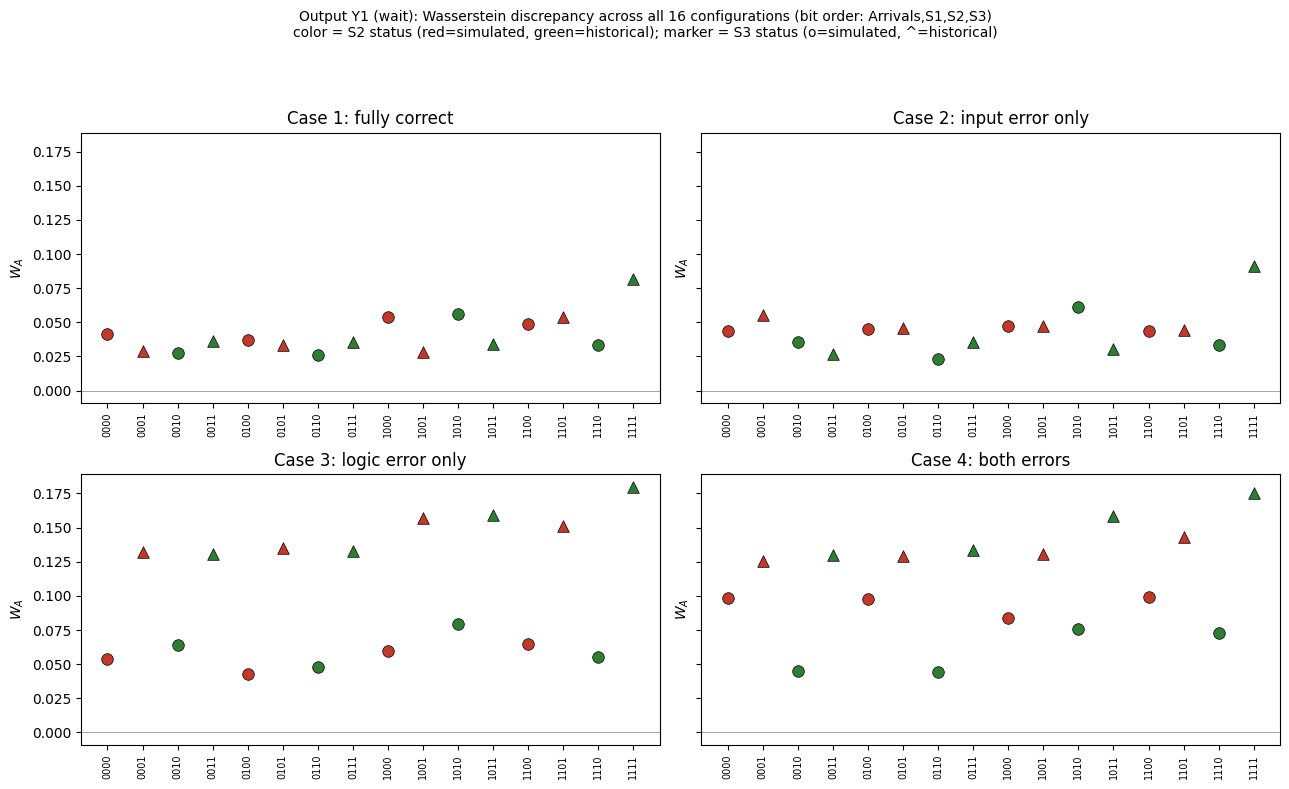

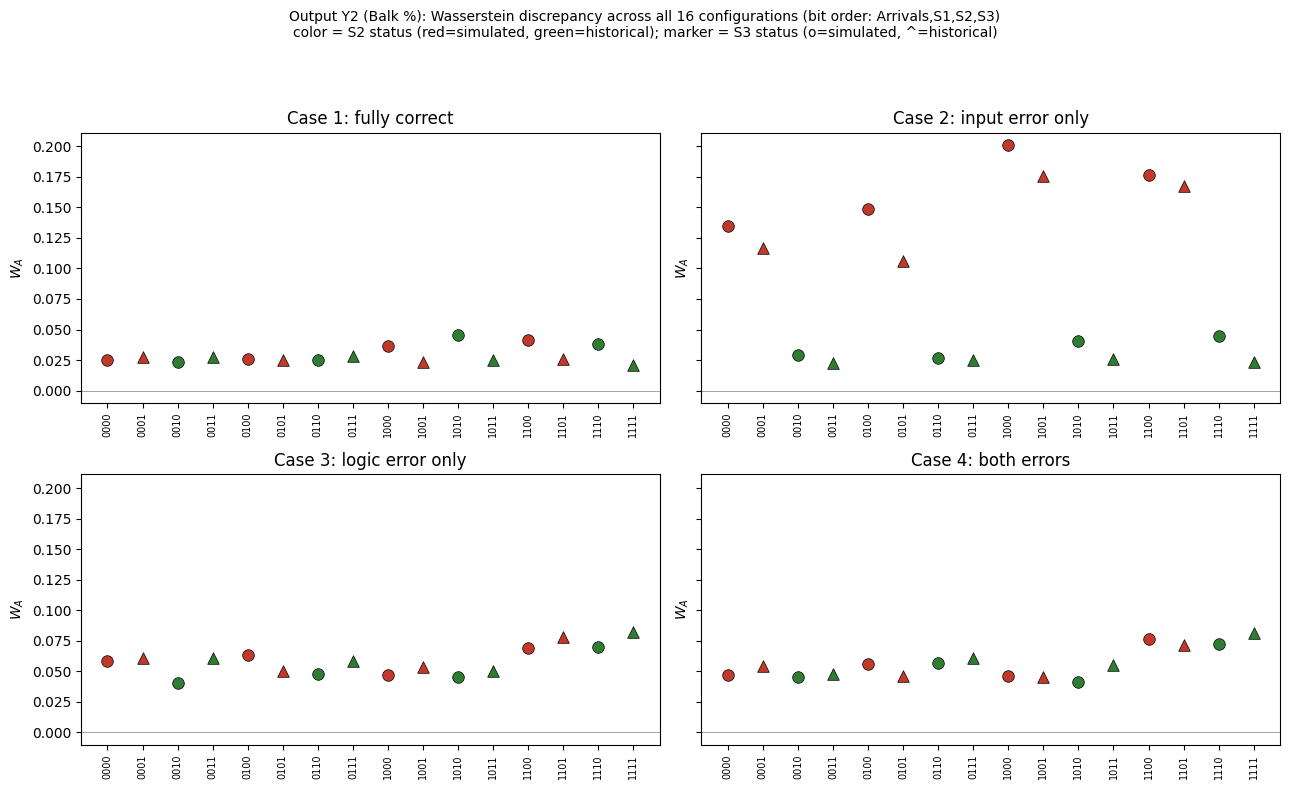

In [10]:
def config_label(bits):
    return ''.join(str(b) for b in bits)

def plot_rgp(w_index, output_label):
    '''w_index: 1 for W_A,1 (wait) or 3 for W_A,2 (Balk %) within each results row tuple.'''
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
    for ax, (case_name, rows) in zip(axes.flat, results.items()):
        bits_list = [r[0] for r in rows]
        W_list = [r[w_index] for r in rows]
        colors = ['#c0392b' if b[2] == 0 else '#2e7d32' for b in bits_list]  # red: S2 sim, green: S2 hist
        markers = ['o' if b[3] == 0 else '^' for b in bits_list]              # circle: S3 sim, triangle: S3 hist
        x = np.arange(len(bits_list))
        for xi, w, c, m in zip(x, W_list, colors, markers):
            ax.scatter(xi, w, color=c, marker=m, s=70, edgecolor='k', linewidth=0.5, zorder=3)
        ax.set_xticks(x)
        ax.set_xticklabels([config_label(b) for b in bits_list], rotation=90, fontsize=7)
        ax.set_title(case_name)
        ax.axhline(0, color='gray', lw=0.5)
        ax.set_ylabel('$W_A$')
    fig.suptitle(f'Output {output_label}: Wasserstein discrepancy across all 16 configurations '
                 '(bit order: Arrivals,S1,S2,S3)\n'
                 'color = S2 status (red=simulated, green=historical); marker = S3 status (o=simulated, ^=historical)',
                 fontsize=10)
    plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

plot_rgp(1, 'Y1 (wait)')
plot_rgp(3, 'Y2 (Balk %)')


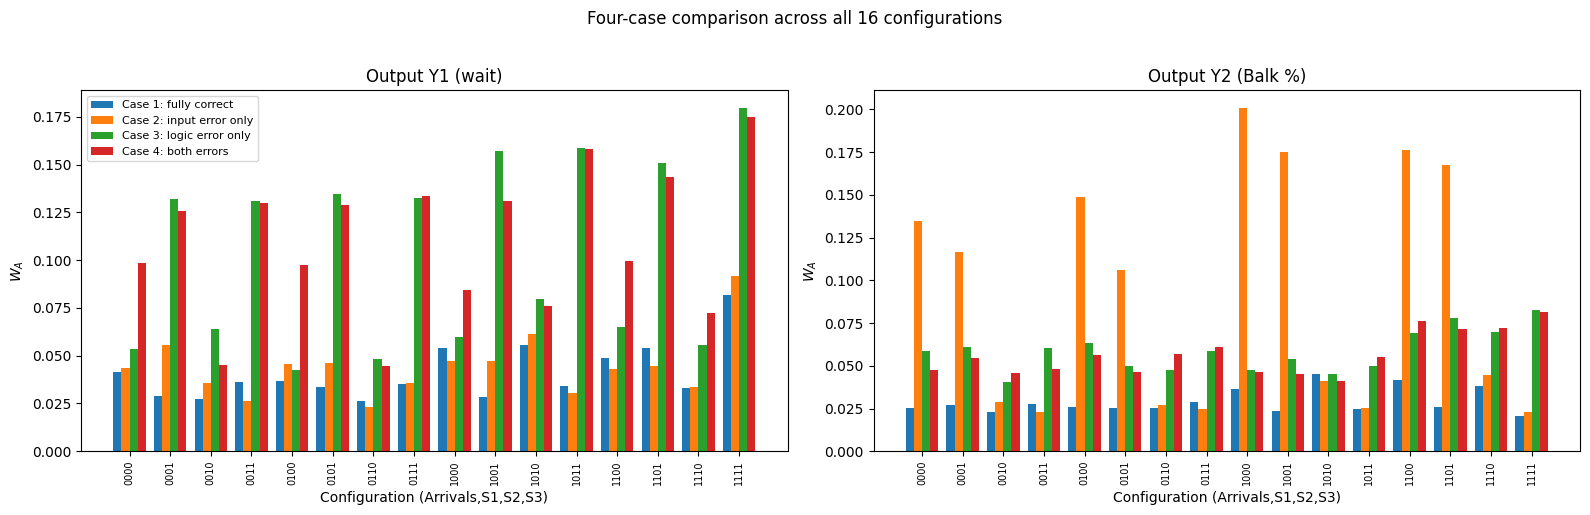

In [11]:
# 4-case comparison, isolating the two diagnostic bits (S2, S3), one panel per output
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
width = 0.2
x = np.arange(16)
for w_index, output_label, ax in [(1, 'Y1 (wait)', axes[0]), (3, 'Y2 (Balk %)', axes[1])]:
    for i, (case_name, rows) in enumerate(results.items()):
        W_list = [r[w_index] for r in rows]
        ax.bar(x + (i - 1.5) * width, W_list, width=width, label=case_name)
    ax.set_xticks(x)
    ax.set_xticklabels([config_label(r[0]) for r in results['Case 1: fully correct']], rotation=90, fontsize=7)
    ax.set_xlabel('Configuration (Arrivals,S1,S2,S3)'); ax.set_ylabel('$W_A$')
    ax.set_title(f'Output {output_label}')
axes[0].legend(fontsize=8)
fig.suptitle('Four-case comparison across all 16 configurations', y=1.02)
plt.tight_layout(); plt.show()


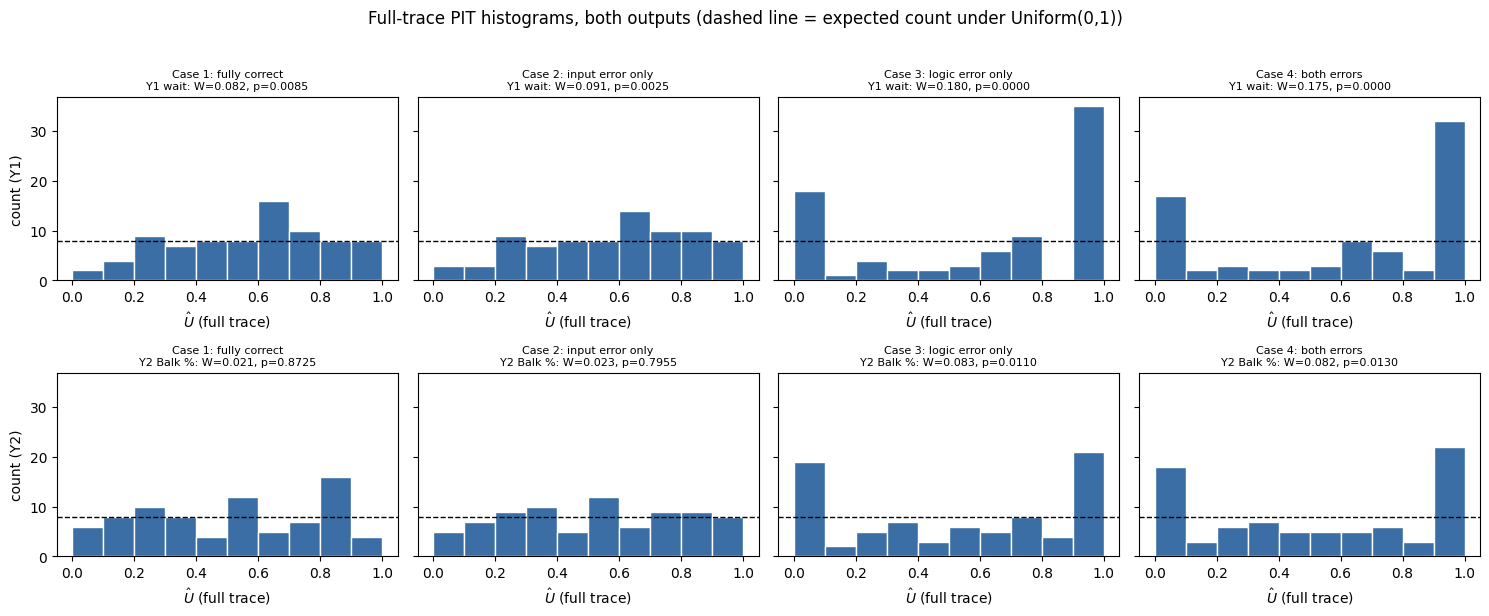

In [12]:
# Full-trace PIT diagnostic for the 4 cases x 2 outputs (the logic-validation test, Section 2.4)
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for col, case_name in enumerate(CASES):
    rows = results[case_name]
    full_row = [r for r in rows if r[0] == (1, 1, 1, 1)][0]
    bits = full_row[0]
    U1, U2, _, _, _ = simulate_config_pit(bits, R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS,
                                           CASES[case_name]['logic'], ARRIVAL_RATE, CASES[case_name]['cand_means'],
                                           psi_list, arrival_hist, service_hist, y_obs1, y_obs2,
                                           SIGMA_EPS1, SIGMA_EPS2, rng)
    for row, (U, wlab) in enumerate([(U1, 'Y1 wait'), (U2, 'Y2 Balk %')]):
        ax = axes[row, col]
        ax.hist(U, bins=10, range=(0, 1), color='#3b6ea5', edgecolor='white')
        ax.axhline(T_PERIODS / 10, color='k', ls='--', lw=1)
        Wv, pv = (full_row[1], full_row[2]) if row == 0 else (full_row[3], full_row[4])
        ax.set_title(f'{case_name}\n{wlab}: W={Wv:.3f}, p={pv:.4f}', fontsize=8)
        ax.set_xlabel('$\\hat U$ (full trace)')
axes[0, 0].set_ylabel('count (Y1)'); axes[1, 0].set_ylabel('count (Y2)')
fig.suptitle('Full-trace PIT histograms, both outputs (dashed line = expected count under Uniform(0,1))', y=1.02)
plt.tight_layout(); plt.show()


## 7. Diagnosing the source(s) of misalignment (Section 3 of the paper)

We now apply the paper's design-of-experiments machinery to **Case 4** (both
errors), the main experiment. The $2^4$ full factorial over
$\mathbf z_A\in\{0,1\}^4$ already gives us $\{(\mathbf z_A, W_A)\}_{A\in\mathcal A}$;
we enrich it via **bootstrapping** the $R$ replicates at each $(t,A)$ (Section
3.1), which lets us quantify the finite-$R$ sampling uncertainty without any
new simulation runs, then fit both:

- a linear model with main effects and all two-way interactions (Section
  3.2), and
- a regression tree, whose variable-importance scores decompose the
  variability in $W_A$ across input processes (Section 3.3),

to see whether they recover the "reject iff S2 simulated OR S3 historical"
structure identified above &mdash; in particular, whether they surface a
large **S2 x S3 interaction** term, or two separate main effects, as the true
generating structure (Section 5 above) suggests they should.

We also add a fifth column, **Logic** (historical = the true blocking rule
$H^*$, simulated = Case 4's wrong candidate rule $H$), and one extra
configuration to go with it: all four inputs historical *and* Logic
historical, i.e. the full-trace replay under the correct logic. That single
row is the "everything matches reality" anchor discussed above &mdash; by
construction it has the smallest $W_{A,1}$ and $W_{A,2}$ of any row in the
dataset, since it is a full-trace deterministic reproduction. Every other
row already in the dataset (the 16 Case-4 configurations) gets Logic =
simulated, since Case 4 always uses the wrong candidate logic. This lets the
regression and the tree attribute misalignment to the logic defect on
exactly the same footing as the four input processes &mdash; run **once per
output**, since the two outputs may implicate different factors.

In [13]:
def bootstrap_biv_W(reps1_matrix, reps2_matrix, y_obs1, y_obs2, B, rng):
    '''Resample each period's R paired replicates with replacement (same
    index applied to both outputs, to preserve pairing; no new simulation),
    recompute the pooled bivariate-PIT Wasserstein statistics B times.'''
    T, R = reps1_matrix.shape
    W1s = np.empty(B); W2s = np.empty(B)
    for b in range(B):
        U1b = np.empty(T); U2b = np.empty(T)
        for t in range(T):
            idx = rng.integers(0, R, size=R)
            U1b[t], U2b[t] = bivariate_conditional_pit(
                reps1_matrix[t, idx], reps2_matrix[t, idx], y_obs1[t], y_obs2[t])
        W1s[b] = wasserstein_uniform(U1b); W2s[b] = wasserstein_uniform(U2b)
    return W1s, W2s


def build_design_matrix(bits_list, process_names):
    Z = np.array(bits_list, dtype=float)
    n, S = Z.shape
    cols, names = [np.ones(n)], ['Intercept']
    for s in range(S):
        cols.append(Z[:, s]); names.append(process_names[s])
    for s in range(S):
        for sp in range(s + 1, S):
            cols.append(Z[:, s] * Z[:, sp]); names.append(f'{process_names[s]}*{process_names[sp]}')
    return np.column_stack(cols), names


DOE_PROCESS_NAMES = PROCESS_NAMES + ['Logic']  # 5th factor, only used in this DoE dataset

# Extra anchor configuration: all 4 inputs historical AND the TRUE logic (rather
# than Case 4's wrong candidate logic). Full-trace + correct logic => deterministic
# reproduction of the true trajectory, so this row should show the smallest W of
# anything in the dataset, for both outputs.
_, _, reps1_true_logic, reps2_true_logic, _ = simulate_config_pit(
    (1, 1, 1, 1), R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS, 'true', ARRIVAL_RATE,
    CASES['Case 4: both errors']['cand_means'], psi_list, arrival_hist, service_hist,
    y_obs1, y_obs2, SIGMA_EPS1, SIGMA_EPS2, rng)

B_BOOTSTRAP = 300
doe_rows, doe_W1, doe_W2 = [], [], []
for bits, (reps1, reps2) in reps_case4.items():
    W1b, W2b = bootstrap_biv_W(reps1, reps2, y_obs1, y_obs2, B_BOOTSTRAP, rng)
    doe_rows.extend([bits + (0,)] * B_BOOTSTRAP)  # Logic=0 (simulated/candidate): Case 4's wrong logic
    doe_W1.extend(W1b.tolist()); doe_W2.extend(W2b.tolist())
W1b_anchor, W2b_anchor = bootstrap_biv_W(reps1_true_logic, reps2_true_logic, y_obs1, y_obs2, B_BOOTSTRAP, rng)
doe_rows.extend([(1, 1, 1, 1, 1)] * B_BOOTSTRAP)   # Logic=1 (historical/true): the anchor row
doe_W1.extend(W1b_anchor.tolist()); doe_W2.extend(W2b_anchor.tolist())

doe_bits = np.array(doe_rows)
doe_W1 = np.array(doe_W1); doe_W2 = np.array(doe_W2)
print(f'Bootstrap-enriched DoE dataset: {len(doe_W1)} rows per output '
      f'({len(reps_case4)} Case-4 configs + 1 true-logic/full-trace anchor row, x {B_BOOTSTRAP} bootstrap draws each).')

for label, doe_W in [('Y1 (wait)', doe_W1), ('Y2 (Balk %)', doe_W2)]:
    X, names = build_design_matrix(doe_bits, DOE_PROCESS_NAMES)
    beta, *_ = np.linalg.lstsq(X, doe_W, rcond=None)
    coef_df = pd.DataFrame({'term': names, 'coefficient': beta}).sort_values('coefficient', key=np.abs, ascending=False)
    print(f'\n=== Output {label}: largest-magnitude regression coefficients ===')
    display(coef_df.head(8))


Bootstrap-enriched DoE dataset: 5100 rows per output (16 Case-4 configs + 1 true-logic/full-trace anchor row, x 300 bootstrap draws each).

=== Output Y1 (wait): largest-magnitude regression coefficients ===


,term,coefficient
0,Intercept,0.103276
13,S2*S3,0.058046
3,S2,-0.052958
7,Arrivals*S2,0.026125
4,S3,0.024086
15,S3*Logic,-0.020215
14,S2*Logic,-0.020215
5,Logic,-0.020215



=== Output Y2 (Balk %): largest-magnitude regression coefficients ===


,term,coefficient
0,Intercept,0.055269
6,Arrivals*S1,0.024128
14,S2*Logic,-0.012081
15,S3*Logic,-0.012081
5,Logic,-0.012081
12,S1*Logic,-0.012081
9,Arrivals*Logic,-0.012081
13,S2*S3,0.010112



=== Output Y1 (wait): regression-tree variable importance ===


,process,importance
3,S3,0.579913
2,S2,0.179444
4,Logic,0.175040
0,Arrivals,0.062499
1,S1,0.003105


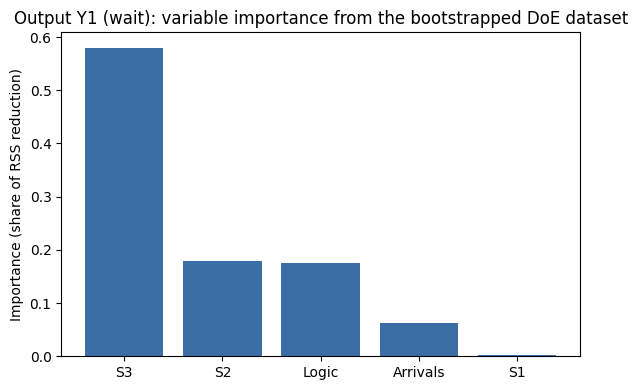

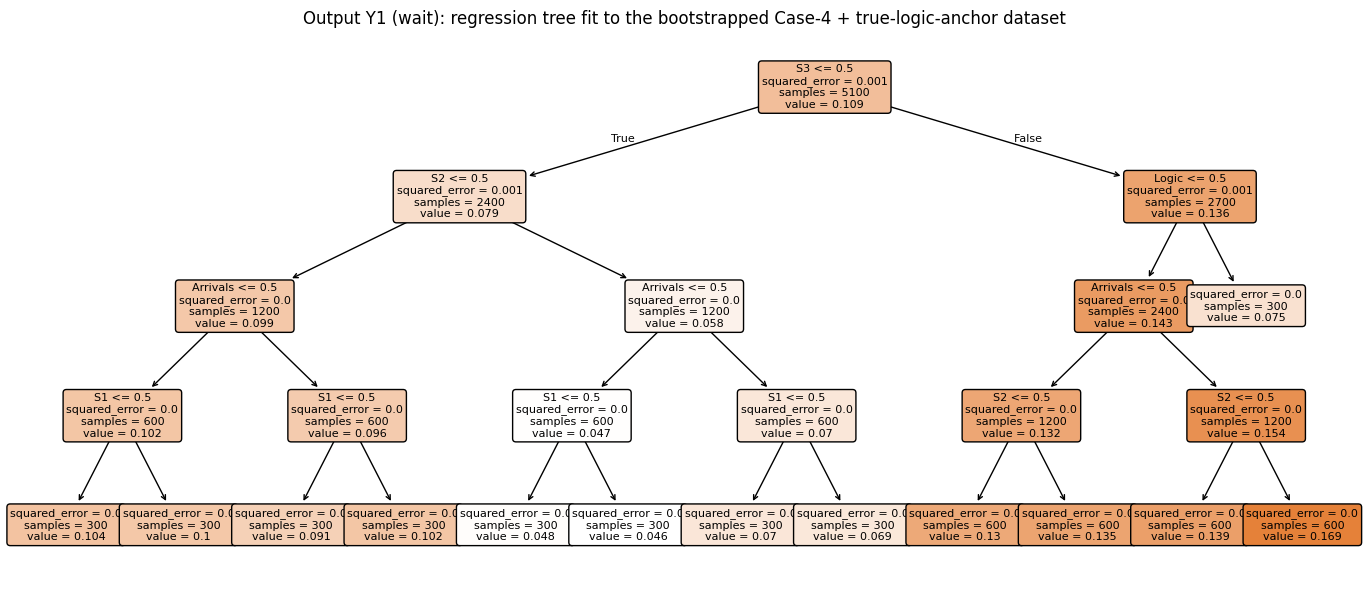


=== Output Y2 (Balk %): regression-tree variable importance ===


,process,importance
4,Logic,0.420259
1,S1,0.284996
0,Arrivals,0.262350
3,S3,0.019889
2,S2,0.012507


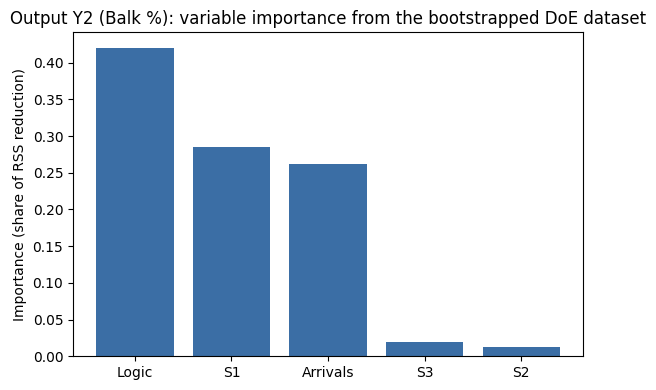

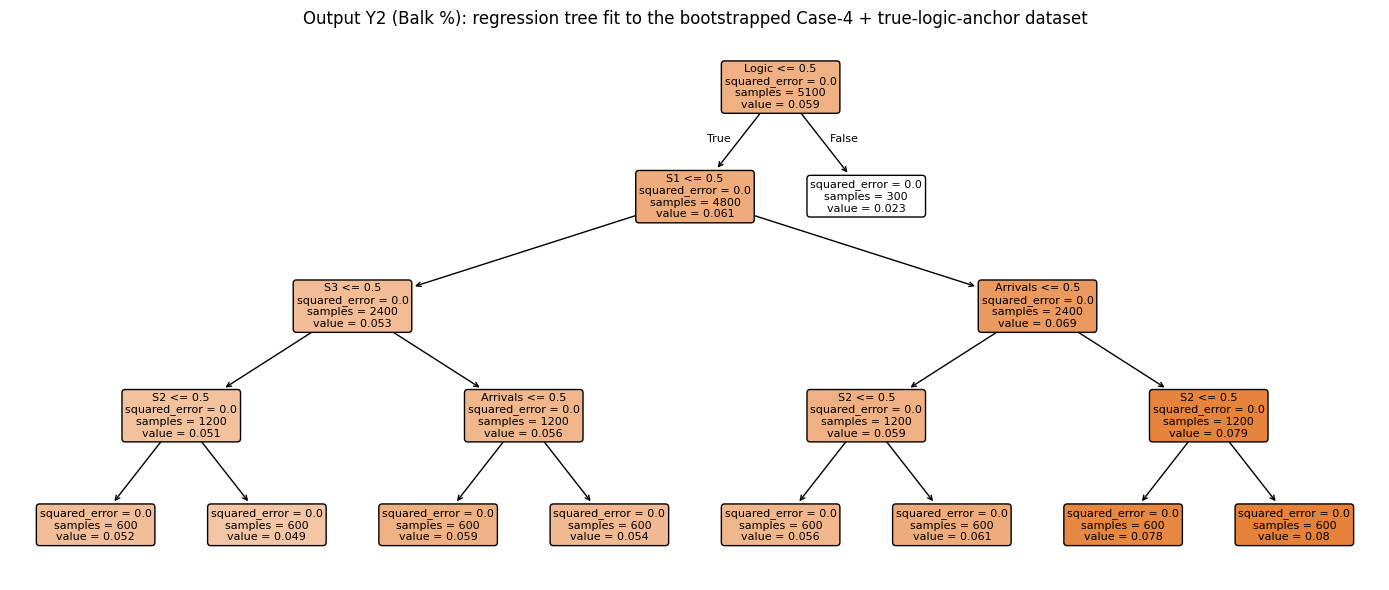

In [14]:
for label, doe_W in [('Y1 (wait)', doe_W1), ('Y2 (Balk %)', doe_W2)]:
    tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=SEED)
    tree.fit(doe_bits, doe_W)
    importances = pd.DataFrame({'process': DOE_PROCESS_NAMES, 'importance': tree.feature_importances_}) \
        .sort_values('importance', ascending=False)
    print(f'\n=== Output {label}: regression-tree variable importance ===')
    display(importances)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(importances['process'], importances['importance'], color='#3b6ea5')
    ax.set_ylabel('Importance (share of RSS reduction)')
    ax.set_title(f'Output {label}: variable importance from the bootstrapped DoE dataset')
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(14, 6))
    plot_tree(tree, feature_names=DOE_PROCESS_NAMES, filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f'Output {label}: regression tree fit to the bootstrapped Case-4 + true-logic-anchor dataset')
    plt.tight_layout(); plt.show()


## 8. Summary of findings

### 8.1 A methodological finding: pooled calibration is not enough

Building the null-calibration pool (Section 3) went through three attempts
before landing on the one used in Section 4, and the failure of the first
two is itself a useful finding, not just a debugging note:

1. **Two reference configurations** ($A=\emptyset$, $A=\mathcal S$), reused
   everywhere. Case 1 (the known-correct model) then rejected at every
   configuration with Arrivals historical and Station 3 simulated, at
   $p<0.001$ &mdash; a clear false-positive problem.
2. **All 16 of Case 1's configurations pooled together** into one
   calibration reference. This did *not* fix it: the same configurations
   still rejected, at essentially the same $p$-values. Diagnosing this
   directly (by comparing the observed conditional-PIT values against the
   candidate replicate distributions period-by-period) showed the cause:
   for these specific configurations, the *observed* $(y_{t1},y_{t2})$
   occasionally falls in a sparse region of *that configuration's own*
   simulated joint distribution, producing a small number of severe outlier
   PIT values (near 0 or 1) that inflate $W$ well beyond what pooling with
   15 better-behaved configurations' calibration draws would lead you to
   expect. This is precisely the failure mode the paper's Section 2.5
   warns about ("the accuracy of the conditional PIT values depends on
   the quality of the KDE... particularly when the observed conditioning
   value lies in a low-density region of the simulated joint
   distribution") &mdash; observed concretely rather than just anticipated.
3. **Per-configuration calibration** (used in Section 4): calibrate each of
   the 16 configurations from *its own* Case-1 replicates only. This
   directly targets the mechanism in (2) and was verified to bring Case 1
   back to nominal (non-significant) rejection everywhere (Section 5's
   Case-1 table).

The practical takeaway for anyone applying Section 2.5's construction: **do
not assume a single calibration reference, or even a pooled one, transfers
across configurations** &mdash; the KDE's finite-sample behavior can depend
on which specific inputs are held fixed, not just on $R$. Calibrate at the
granularity you test.

### 8.2 Comparing the two outputs: a clean split in isolation, a genuine interaction combined

The univariate notebook found that $Y_1$ (mean waiting time) alone detects
*both* defects, but only through Station 3's status: the input error
(Station 2) is invisible unless Station 3 is *also* fixed, and the logic
error requires Station 3 fixed as well. With the bivariate KDE test and
per-configuration calibration, a sharper and more informative picture
emerges from the actual executed results (Section 5's tables):

- **In isolation, the two outputs split the two defects almost perfectly.**
  In Case 2 (input error only), $Y_2$ (balk %) rejects at **exactly** the 8
  configurations with Station 2 simulated and at none of the 8 with Station
  2 historical &mdash; a clean main effect, and a *much* sharper signature
  than $Y_1$ ever showed for this defect (which barely reacts to Case 2 at
  all: no configuration reaches significance). In Case 3 (logic error
  only), $Y_1$ rejects at essentially every configuration with Station 3
  historical (matching the univariate notebook's finding), while $Y_2$
  reacts to the logic defect only at the full-trace test.
- **Case 1 (fully correct) rejects nowhere** at the Holm-corrected level,
  for either output, at any of the 15 non-trivial configurations &mdash;
  confirming the per-configuration calibration fix in Section 8.1 holds
  across the whole design, not just the one configuration used to diagnose
  it. (The single full-trace logic test for $Y_1$ does reject at
  $p=0.0085$; that test is deliberately *not* Holm-corrected, as it is
  reported separately per Section 2.4, so an isolated false positive at
  roughly the nominal rate is expected behavior, not a calibration
  failure.)
- **Combined (Case 4), the split is not simply additive.** $Y_1$ still
  cleanly flags every Station-3-historical configuration, exactly as in
  Case 3. But $Y_2$'s clean Station-2 signature from Case 2 **collapses**:
  none of the 8 Station-2-simulated configurations survive Holm correction
  in Case 4, though their raw $p$-values still trend lower than the
  Station-2-historical configurations. This is not noise, and not a
  calibration problem &mdash; it has a direct mechanistic explanation. The
  channel that let $Y_2$ detect the input error in Case 2 is backpressure:
  under the *correct* (blocking) logic, a slow Station 2 fills its own
  buffer, which blocks Station 1's server, which fills Station 1's (now
  tight) buffer and drives up balking. The wrong logic's *entire defect* is
  that Station 1's server is never blocked (completed jobs go to an
  unbounded holding area instead). Once that defect is present, the very
  backpressure channel that made balk % sensitive to Station 2 is
  structurally severed, regardless of how badly Station 2 is misspecified.

The lesson is more interesting than "two outputs beat one": which output
carries a given defect's signature can depend on a *physical mechanism*
that a different defect can independently disable. A modeler seeing Case
4's pattern (clean $Y_1$ signature, muddled $Y_2$ signature) and taking it
at face value could underweight the Station-2 evidence precisely because
the logic defect they're also chasing has masked it. This argues for
running the diagnostic per-defect-hypothesis where feasible (e.g., Case 2
and Case 3-style ablations) rather than reading the combined case alone.